# 02 Preprocessing
This notebook turns the raw rows into cleaned product records and shows the effect of each step with before-and-after charts. All logic lives in `product_similarity.data` and `product_similarity.preprocessing`; the notebook only runs it and plots the results.

The raw archive is never changed: it is read in place, and the hash check below confirms it is still the file supplied with the exercise.

Not decided here, because they need experiments: price scaling, how rating is used, how much to clean titles, how missing values are scored, and the similarity weights.

**Why some numbers differ slightly from notebook 01:** notebook 01 counts all 30,000 rows, while this notebook counts the 29,529 products left after repeats are removed, and it counts a brand or colour only when it is usable after cleaning. For example, rated-but-unreviewed products are 6,611 in notebook 01 and 6,571 here, price is present for 90.4% there and 90.2% here, and brand for 72.9% there and 72.8% here.

In [1]:
import collections as C
import random
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from product_similarity.data import canonicalize, check_integrity, load_products
from product_similarity.preprocessing import (
    build_brand_lookup,
    build_brand_map,
    build_products,
    clean_brand,
    derive_audience,
    parse_weight,
    primary_category,
    recover_brand_from_title,
)

root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
archive = root / "data" / "archive.zip"
plt.rcParams.update(
    {"figure.figsize": (7, 3.5), "axes.spines.top": False, "axes.spines.right": False}
)
BLUE, GREY, ORANGE = "#4c78a8", "#c7c7c7", "#f58518"
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.width", 160)
rng = random.Random(3)

print("Archive is still SAP's original file:", check_integrity(archive))
rows = load_products(archive)
kept, id_map = canonicalize(rows)
products, report = build_products(kept)
print(f"{len(rows):,} raw rows -> {len(kept):,} products")

Archive is still SAP's original file: True


30,000 raw rows -> 29,529 products


## 1. Repeated products
The same ASIN appears in several rows because the product was crawled more than once.

All 30,000 original IDs resolve to one of 29,529 kept products.


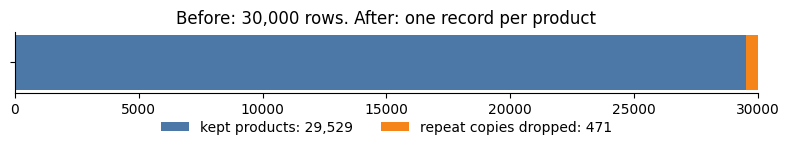

,uniq_id,crawled,price,kept
0,526d18a68f0e590d230d74aedb0b28da,2020-02-06 05:09:56 +0000,440.0,False
1,a33e6b06e2bf594bddaed958a747b31b,2020-02-06 11:37:51 +0000,440.0,False
2,1c2994f5f4c2d458376610c635cc6a8a,2020-02-07 11:27:27 +0000,440.0,True


In [2]:
assert set(id_map) == {r["uniq_id"] for r in rows}, "every original ID must still resolve"
assert set(id_map.values()) <= {r["uniq_id"] for r in kept}
print(f"All {len(id_map):,} original IDs resolve to one of {len(kept):,} kept products.")

fig, ax = plt.subplots(figsize=(8, 1.8))
ax.barh([""], [len(kept)], color=BLUE, label=f"kept products: {len(kept):,}")
ax.barh(
    [""],
    [len(rows) - len(kept)],
    left=[len(kept)],
    color=ORANGE,
    label=f"repeat copies dropped: {len(rows) - len(kept)}",
)
ax.set_xlim(0, len(rows))
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=2, frameon=False)
ax.set_title("Before: 30,000 rows. After: one record per product")
plt.tight_layout()
plt.show()

by_asin = C.defaultdict(list)
for r in rows:
    by_asin[r["asin"]].append(r)
example = next(g for g in by_asin.values() if len(g) == 3)
display(
    pd.DataFrame(
        {
            "uniq_id": [r["uniq_id"] for r in example],
            "crawled": [r["crawl_timestamp"] for r in example],
            "price": [r["sales_price"] for r in example],
            "kept": [id_map[r["uniq_id"]] == r["uniq_id"] for r in example],
        }
    )
)

### What this shows and what we do about it
Repeat rows are re-collected copies of one product, and their prices sometimes differ. Keeping both would let a product match itself in the results.
**What I do:** keep the most recently crawled row for each ASIN (lowest `uniq_id` if tied) and map every old ID to it, so the API still accepts all 30,000 IDs.

## 2. Weight
The placeholder `999999999` hides that few products have a real weight, and a few real values are impossible.

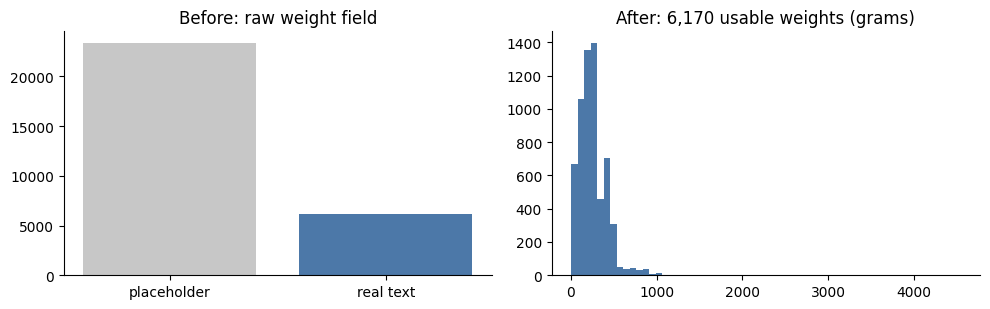

Why values were not used: {'placeholder': 23350, 'not_a_weight': 1, 'out_of_range': 8}


,raw weight,product
0,The Slim N Lift slimming shirt even smoothest out your back for a ...,TRENDBUY Men's Slim Lift Slimming Tummy Trimmer Tu
1,113 Kilograms,"1782 , Large , Charcoal : Truform 1782, Women's Do"
2,136 Kilograms,"X-Large , Beige : Truform 15-20 mmHg Knee High, Op"
3,136 Kilograms,"Medium , Beige : Truform 15-20 mmHg Knee High, Clo"
4,113 Kilograms,"1783 , Small , Black : Truform 1783, Women's Diamo"
5,113 Kilograms,"Black , 3X-Large : Truform Women's 15-20 mmHg Shee"
6,113 Kilograms,"Truform 1782, Women's Dot Pattern (15-20 mmHg) Gra"
7,136 Kilograms,"White , 3X-Large : Truform 30-40 mmHg Knee High, C"
8,136 Kilograms,"X-Large , Black : Truform Women's 15-20 mmHg Knee"


In [3]:
raw_weights = pd.Series([r["weight"] for r in kept])
parsed = [parse_weight(w) for w in raw_weights]
grams = pd.Series([g for g, _ in parsed]).dropna()
problems = C.Counter(p for _, p in parsed if p)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].bar(
    ["placeholder", "real text"],
    [problems["placeholder"], len(kept) - problems["placeholder"]],
    color=[GREY, BLUE],
)
axes[0].set_title("Before: raw weight field")
axes[1].hist(grams, bins=60, color=BLUE)
axes[1].set_title(f"After: {len(grams):,} usable weights (grams)")
plt.tight_layout()
plt.show()

print("Why values were not used:", dict(problems))
bad = [
    (r["weight"], r["product_name"][:50])
    for r, (_, p) in zip(kept, parsed)
    if p in ("out_of_range", "not_a_weight")
]
display(pd.DataFrame(bad, columns=["raw weight", "product"]))

### What this shows and what we do about it
About four in five products have no weight, and the few impossible values (for example 136 kilograms on a pair of stockings) would distort any comparison.
**What I do:** treat the placeholder as missing, convert units to grams, and reject values outside 1 g to 5 kg. Rejected values are counted and listed, not hidden. How much weight should matter is tested later.

## 3. Brand
The same brand is spelled several ways, and some values are placeholders.

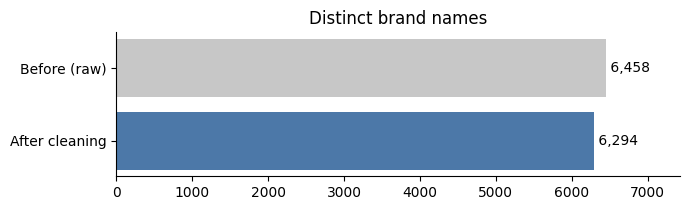

66 placeholder brands (Unknown, N/A) became missing.
156 brand names had more than one spelling. Largest merges:


,kept spelling,spellings merged
0,nauti nati,Nautinati | nauti nati
1,RAPID DOMINANCE,RAPID DOMINANCE | Rapid Dominance
2,IndiWeaves,IndiWeaves | indi weaves
3,uniq,Uniq | uniq
4,Flex fit,Flex fit | Flexfit
5,Baby Doll,Baby Doll | Babydoll
6,Golden Girl,GOLDEN GIRL | Golden Girl
7,Neska Moda,Neska Moda | NeskaModa
8,C.C,C&C | C.C
9,CHRYSOLITE,CHRYSOLITE | Chrysolite


In [4]:
raw_brands = [r.get("brand") for r in kept if r.get("brand")]
cleaned = [clean_brand(b) for b in raw_brands]
mapping = build_brand_map([b for b in cleaned if b])
counts = C.Counter(b for b in cleaned if b)

merged = C.defaultdict(list)
for spelling, canon in mapping.items():
    merged[canon].append(spelling)
groups = sorted(
    ((c, s) for c, s in merged.items() if len(s) > 1), key=lambda cs: -sum(counts[x] for x in cs[1])
)

fig, ax = plt.subplots(figsize=(7, 2.2))
vals = [len(set(raw_brands)), len({p.brand for p in products if p.brand})]
ax.barh(["After cleaning", "Before (raw)"], vals[::-1], color=[BLUE, GREY])
for i, v in enumerate(vals[::-1]):
    ax.text(v, i, f" {v:,}", va="center")
ax.set_xlim(0, max(vals) * 1.15)
ax.set_title("Distinct brand names")
plt.tight_layout()
plt.show()

print(f"{report.brand_placeholders} placeholder brands (Unknown, N/A) became missing.")
print(f"{len(groups)} brand names had more than one spelling. Largest merges:")
display(
    pd.DataFrame(
        [(c, " | ".join(sorted(s))) for c, s in groups[:10]],
        columns=["kept spelling", "spellings merged"],
    )
)

### What this shows and what we do about it
Spelling variants would make one brand look like several, so two products from the same brand would not count as matching.
**What I do:** merge spellings that differ only in capitals, spaces or punctuation, keep the most common one, and turn placeholders into missing. The merges above are listed so they can be reviewed. Brand coverage stays at the original level, because nothing is guessed here.

## 4. Category
Some products have no leaf category, but they do have a browse node that other products share.

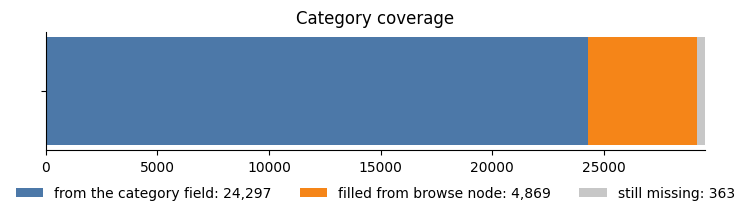

Held-out check: the browse node recovers the true category for 23,015 of 23,827 products (96.6%).
Examples where it guessed wrong:


,product,true category,guessed
0,US Polo Association Women's Sweater,MaternityWinterwear,WomensPulloverSweaters
1,Dummy Shape Women's Maternity cum Feeding Caramel,MaternityKurtasKurtis,WomensKurtasKurtis
2,RAAYA Shawls For Women And Girls Designer Stoles F,WomensChunnisDupattas,WomensClothing
3,Marks & Spencer Women's Plain/Solid Full Slip,WomensNightiesNightdresses,WomensCamisolesTanks
4,Peppermint Girl's Plain Regular fit Shirt,GirlsShirts,BoysShirts
5,Boys Slim Fit Classic Blue Denims,PottyTrainingStepStools,GirlsKnickers
6,People Women's Regular fit Top,WomensT_Shirts,WomensTops
7,Puma Men's T-Shirt,MensT_Shirts,MensSportsT_ShirtsJerseys
8,Indian Terrain Boy's Shorts,BoysShorts,BoysSportsShorts
9,Indian Terrain Boys' Plain Regular Fit T-Shirt,BoysT_Shirts,BoysSweatshirtsHoodies


In [5]:
cov = pd.Series(
    {
        "from the category field": report.category_from_child,
        "filled from browse node": report.category_from_node,
        "still missing": report.category_missing,
    }
)
fig, ax = plt.subplots(figsize=(8, 2.4))
left = 0
for (label, v), colour in zip(cov.items(), [BLUE, ORANGE, GREY]):
    ax.barh([""], [v], left=[left], color=colour, label=f"{label}: {v:,}")
    left += v
ax.set_xlim(0, len(kept))
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3, frameon=False)
ax.set_title("Category coverage")
plt.tight_layout()
plt.show()

# Hide each product's known category and predict it from its browse node.
votes = C.defaultdict(C.Counter)
for r in kept:
    c, n = primary_category(r), r.get("browsenode")
    if c and n:
        votes[n][c] += 1
hits = total = 0
misses = []
for r in kept:
    c, n = primary_category(r), r.get("browsenode")
    if not (c and n):
        continue
    v = +(votes[n] - C.Counter({c: 1}))
    if not v:
        continue
    guess = sorted(v.items(), key=lambda kv: (-kv[1], kv[0]))[0][0]
    total += 1
    hits += guess == c
    if guess != c:
        misses.append((r["product_name"][:50], c, guess))
print(
    f"Held-out check: the browse node recovers the true category for {hits:,} of {total:,} products ({hits / total:.1%})."
)
print("Examples where it guessed wrong:")
display(pd.DataFrame(rng.sample(misses, 10), columns=["product", "true category", "guessed"]))

### What this shows and what we do about it
Category is the strongest structured signal, and filling it from the browse node covers almost every product. The check hides a known category and guesses it back, and it is right about 97% of the time. The wrong guesses are mostly neighbouring categories (for example a T-shirt filed as a top), not unrelated ones.
**What I do:** use the browse-node category only when the category field is missing, and record where each category came from so it can be treated with less trust if needed. About 1% of products stay without a category.

## 5. Colour
The colour field lists variants, so the title is a second source for the product's own colour.

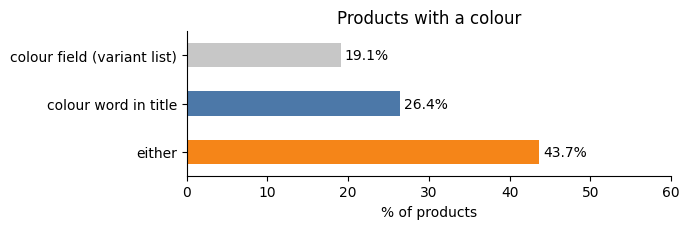

Where both exist (529 products), the title colour is among the listed options for 441 (83.4%).
Cases where they disagree:


,title,title colour,listed options
0,ALBATROZ Racerback Padded Sports Bra Sports Gym Yoga Da,peach,"black, blue, green, grey, pink"
1,Pacific Gold Men's Leather Belt,gold,"black, brown"
2,TheShoppingDiary Splicing Color Block Black Monokini,black,"grey, pink, purple, yellow"
3,Casotec Music Therapy Designer Polyester Sports Round N,blue,"green, white, yellow"
4,Pacific Gold Automatic Autolock Buckle Genuine Leather,gold,"black, brown"
5,Gadgets Appliances Shirts Light Pink,pink,"blue, green, orange, yellow"
6,Wild Thunder T Shirt - Just Bring It Logo Printed Cotto,black,"gold, green, orange, red, silver"
7,Pink Wings Girls Frock (Brooch),pink,"blue, purple, red, turquoise, wine"


A random sample of title colours for review:


,title,found
0,Monte Carlo Grey Solid Cotton Blend Hood Sweatshirt,grey
1,"NEO NATIVES Boys Shirt, Kids Designer Chinese Collar Shirt, Casual...","navy, red"
2,PINK N BLUE By FBB Boy's Checkered Regular Fit Shirt,"blue, pink"
3,Ansh Boutique Women's Georgette Saree With Blouse Piece (Yellow),yellow
4,Ethnic Girls Women's Chanderi Pink Gold Foil Print Straight Kurta ...,"gold, pink"
5,Faux Leather Belt with Nickel Buckle - Black 60,black
6,Damyantii Women’s Red and Blue Cotton long kurti for women in size...,"blue, red"
7,WYKBPX Adjustable Bubba Gump Baseball Cap Shrimp Co. Embroidered H...,red
8,"Baby Girls Christmas 3 Piece Set,Bodysuit,Red Striped Ankle Socks,...","red, white"
9,Yashika women's art silk kalamkari and bhagalpuri style saree with...,green


In [6]:
have_title = sum(1 for p in products if p.title_colours)
have_listed = sum(1 for p in products if p.listed_colours)
have_any = sum(1 for p in products if p.title_colours or p.listed_colours)
cov = (
    pd.Series(
        {
            "colour field (variant list)": have_listed,
            "colour word in title": have_title,
            "either": have_any,
        }
    )
    / len(products)
    * 100
)
ax = cov.iloc[::-1].plot.barh(color=[ORANGE, BLUE, GREY], figsize=(7, 2.4))
for i, v in enumerate(cov.iloc[::-1]):
    ax.text(v + 0.5, i, f"{v:.1f}%", va="center")
ax.set_xlim(0, 60)
ax.set_xlabel("% of products")
ax.set_title("Products with a colour")
plt.tight_layout()
plt.show()

both = [p for p in products if p.title_colours and p.listed_colours]
agree = [p for p in both if set(p.title_colours) & set(p.listed_colours)]
print(
    f"Where both exist ({len(both)} products), the title colour is among the listed options for {len(agree)} ({len(agree) / len(both):.1%})."
)
print("Cases where they disagree:")
dis = [p for p in both if not set(p.title_colours) & set(p.listed_colours)]
display(
    pd.DataFrame(
        [
            (p.title[:55], ", ".join(p.title_colours), ", ".join(p.listed_colours[:5]))
            for p in rng.sample(dis, 8)
        ],
        columns=["title", "title colour", "listed options"],
    )
)
print("A random sample of title colours for review:")
display(
    pd.DataFrame(
        [
            (p.title[:70], ", ".join(p.title_colours))
            for p in rng.sample([p for p in products if p.title_colours], 10)
        ],
        columns=["title", "found"],
    )
)

### What this shows and what we do about it
Reading colour words from the title more than doubles the share of products with a colour, from about 19% (recognised colour words in the field) to about 44%, and the two sources mostly agree. The disagreements are mixed: some are real conflicts (a "Blue" saree listed as orange, pink or red), and some are fine because the listed options are other variants of the same product. Wrong guesses are possible (for example "Gold" in a brand or a plated item).
**What I do:** keep the title colour and the listed colours as two separate fields and treat both as weak evidence. How much they matter is tested later.

## 6. Audience (men, women, boys, girls, baby)
Shoppers do not treat a men's shirt and a girl's dress as similar, so the audience is worth knowing.

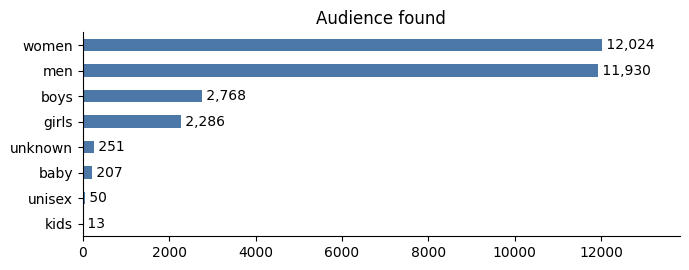

Category and title both give an audience for 23,670 products and agree for 21,159 (89.4%).
Most common disagreements (category says, title says): [(('girls', 'baby'), 579), (('men', 'unisex'), 457), (('women', 'unisex'), 379), (('boys', 'baby'), 318), (('boys', 'kids'), 99)]


,title,category says,title says
0,blippi llc Kid's Adjustable and Clip on Suspenders and Bow T,men,kids
1,My Lil Princess Baby Girls Birthday Party wear Frock Dress_B,girls,baby
2,"Beebay Infant-Girl 97% Cotton, 3% Elastane Flower Embroidery",girls,baby
3,Michelangelo Boy/Men's MAROON Slim Tie,men,unisex
4,My Lil Princess Baby Girl's Cute and Pretty Kids Fairy Frock,girls,baby
5,Pantaloons Baby Boy's Tribal Regular fit T-Shirt,boys,baby
6,FristClap Denim Full Length Dungaree for Boys & Girls|Dress,girls,unisex
7,"Krystle Boy's and Girl's Printed Cotton Socks (Multicolour,",boys,unisex


Products with no audience found:


,title
0,AURION GYMGLOVE-9999 Power Muscle All Leather Gym Glove with Wrist...
1,Xtrim Unisex Macho Leather Gym Workout Wrist Wrap Gloves
2,"Strauss Stretch-Back Gym Gloves with Leather Palm, (Medium)"
3,DreamBag Couple T Shirts - Soulmate Unisex Couple T-Shirts
4,Mamma's Maternity Rayon Printed Maternity Dress
5,HETASH Unisex Nylon Fingerless Arm Sleeves with Thumb Hole for Spo...


In [7]:
aud = pd.Series([p.audience or "unknown" for p in products]).value_counts()
ax = aud.iloc[::-1].plot.barh(color=BLUE, figsize=(7, 2.8))
for i, v in enumerate(aud.iloc[::-1]):
    ax.text(v, i, f" {v:,}", va="center")
ax.set_xlim(0, aud.max() * 1.15)
ax.set_title("Audience found")
plt.tight_layout()
plt.show()

pairs = [(p, derive_audience("", p.category), derive_audience(p.title, None)) for p in products]
pairs = [(p, a, b) for p, a, b in pairs if a and b]
same = sum(1 for _, a, b in pairs if a == b)
print(
    f"Category and title both give an audience for {len(pairs):,} products and agree for {same:,} ({same / len(pairs):.1%})."
)
dis = [(p, a, b) for p, a, b in pairs if a != b]
print(
    "Most common disagreements (category says, title says):",
    C.Counter((a, b) for _, a, b in dis).most_common(5),
)
display(
    pd.DataFrame(
        [(p.title[:60], a, b) for p, a, b in rng.sample(dis, 8)],
        columns=["title", "category says", "title says"],
    )
)
print("Products with no audience found:")
display(
    pd.DataFrame(
        [(p.title[:70],) for p in rng.sample([p for p in products if not p.audience], 6)],
        columns=["title"],
    )
)

### What this shows and what we do about it
Almost every product gets an audience. The category and the title agree about 89% of the time. Most disagreements are different levels of detail (the category says "girls" while the title says "baby girls") or a title that names several groups; a few are wrong category labels (a boys' bow tie filed under men).
**What I do:** use the category first and the title as a fallback, and use audience as a hint, not a strict filter. About 1% of products have no audience.

## 7. Reviews and rating
The rating field cannot tell a product with no reviews from one with many.

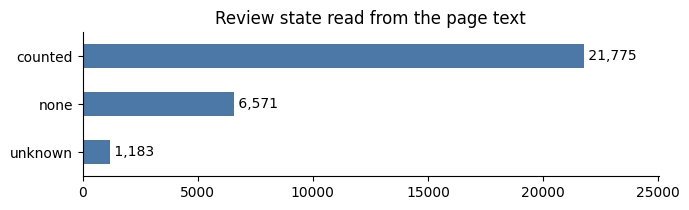

6,571 products show a rating but the page says nobody has reviewed them.


In [8]:
state = pd.Series([p.review_state for p in products]).value_counts()
ax = state.iloc[::-1].plot.barh(color=BLUE, figsize=(7, 2.2))
for i, v in enumerate(state.iloc[::-1]):
    ax.text(v, i, f" {v:,}", va="center")
ax.set_xlim(0, state.max() * 1.15)
ax.set_title("Review state read from the page text")
plt.tight_layout()
plt.show()
no_reviews_rated = sum(1 for p in products if p.review_state == "none" and p.rating is not None)
print(f"{no_reviews_rated:,} products show a rating but the page says nobody has reviewed them.")

### What this shows and what we do about it
Many products carry a rating that nothing backs up. Separating "no reviews", "counted" and "unknown" gives the rating a reliability signal.
**What I do:** keep the raw rating, the page rating and the review count side by side. How they are combined, and how much weight rating gets, is decided later by experiment.

## 8. Price
Price is kept as it is, with a log version added next to it.

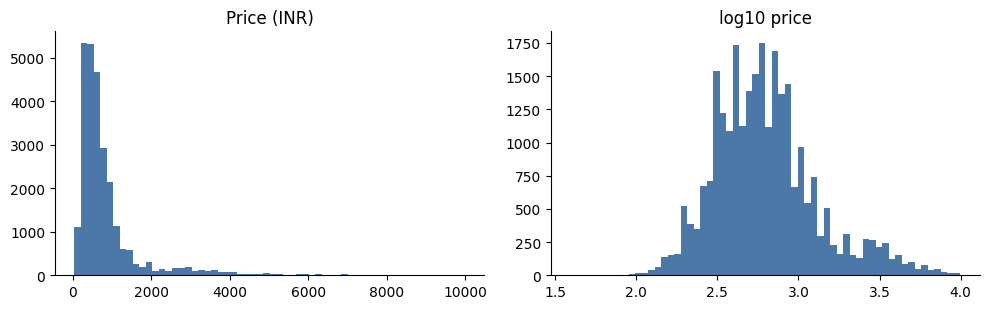

26,640 of 29,529 products have a price; the rest stay missing.


In [9]:
priced = [p for p in products if p.price]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].hist([p.price for p in priced], bins=60, color=BLUE)
axes[0].set_title("Price (INR)")
axes[1].hist([p.log_price for p in priced], bins=60, color=BLUE)
axes[1].set_title("log10 price")
plt.tight_layout()
plt.show()
print(f"{len(priced):,} of {len(products):,} products have a price; the rest stay missing.")

### What this shows and what we do about it
The log version is far more balanced than the raw one. Missing prices are not filled in.
**What I do:** store both versions. Which one to compare, and whether to scale within a category, is tested later.

## 9. Brand recovery from titles (switched off)
Many titles start with the brand, so a missing brand could be read from the title. This is checked here but stays off.

In [10]:
brand_counts = C.Counter(p.brand for p in products if p.brand)
lookup = build_brand_lookup([b for b, c in brand_counts.items() if c >= 2])
tests = []
for p in products:
    if p.brand:
        guess = recover_brand_from_title(p.title, lookup)
        if guess:
            tests.append((p, guess))


def norm(s):
    return "".join(ch for ch in s.lower() if ch.isalnum())


right = [(p, g) for p, g in tests if norm(g) == norm(p.brand)]
known = sum(brand_counts.values())
print(f"Held-out check on {known:,} products that have a brand (their brand hidden):")
print(
    f"  recovered {len(tests):,}; correct {len(right):,}; precision {len(right) / len(tests):.1%}; recall {len(right) / known:.1%}"
)
wrong = [(p, g) for p, g in tests if norm(g) != norm(p.brand)]
display(
    pd.DataFrame(
        [(p.title[:55], p.brand[:40], g) for p, g in rng.sample(wrong, 10)],
        columns=["title", "true brand", "recovered"],
    )
)
_, with_recovery = build_products(kept, recover_brands=True)
print(
    f"If switched on, it would fill {with_recovery.brand_recovered:,} of the {sum(1 for p in products if not p.brand):,} missing brands."
)

Held-out check on 21,492 products that have a brand (their brand hidden):


  recovered 16,285; correct 15,999; precision 98.2%; recall 74.4%


,title,true brand,recovered
0,"Outdoor Designs Polarfleece Beanie, Charcoal",Outdoor Designs,OUTDOOR
1,Dhrona Men's Plain Color Cotton Lungies for Occasions,Generic,Dhrona
2,Angel Dear Baby-girls Infant Chenille Hooded Jacket,Angel Dear,Angel
3,Lux Lyra Women's Churidar Leggings,Pistaa's,LUX LYRA
4,Charm n Cherish Kids Boxers (Pack of 3) Striped (BWBXI1,CHARM N CHERISH,Charm
5,Marvel Comics Avengers Assemble Seatbelt Belt,Buckle Down,Marvel
6,Champion Women's Absolute Shape Sports Bra with SmoothT,Champion fbb,Champion
7,RARE ROOTS Women's Pleated Maxi Dress,RARE ROOTS,RARE
8,DHRUVI TRENDZ Women's Anarkali Kurta,Leriya Fashion,DHRUVI TRENDZ
9,"Feranoid Men's Quote Printed Regular Fit,Half Sleeves,R",Feranoid Clothing,FERANOID


If switched on, it would fill 2,087 of the 8,037 missing brands.


### What this shows and what we do about it
On products whose brand is known, reading it from the title is right about 98% of the time. The mistakes are mostly shorter or longer versions of the right brand ("Champion" for "Champion Sports") and a few real mix-ups. But this check only covers products that already have a brand, and products without one may be different (for example unbranded items), so the real accuracy could be lower.
**What I do:** keep it switched off. It can be turned on later if a review of a sample of the actual recoveries confirms it, or tested as an experiment.

## 10. Coverage after cleaning

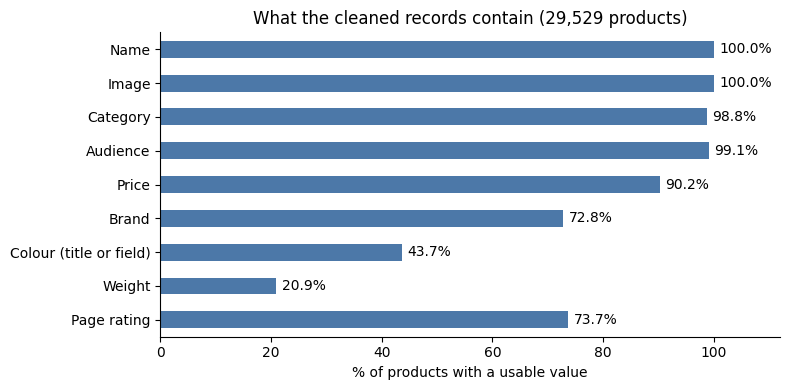

In [11]:
n = len(products)
cov = pd.Series(
    {
        "Name": 100.0,
        "Image": sum(p.image_url is not None for p in products) / n * 100,
        "Category": sum(p.category is not None for p in products) / n * 100,
        "Audience": sum(p.audience is not None for p in products) / n * 100,
        "Price": sum(p.price is not None for p in products) / n * 100,
        "Brand": sum(p.brand is not None for p in products) / n * 100,
        "Colour (title or field)": sum(bool(p.title_colours or p.listed_colours) for p in products)
        / n
        * 100,
        "Weight": sum(p.weight_g is not None for p in products) / n * 100,
        "Page rating": sum(p.page_rating is not None for p in products) / n * 100,
    }
)
ax = cov.iloc[::-1].plot.barh(color=BLUE, figsize=(8, 4))
for i, v in enumerate(cov.iloc[::-1]):
    ax.text(v + 1, i, f"{v:.1f}%", va="center")
ax.set_xlim(0, 112)
ax.set_xlabel("% of products with a usable value")
ax.set_title(f"What the cleaned records contain ({n:,} products)")
plt.tight_layout()
plt.show()

### What this shows and what we do about it
The cleaned records are strongest on name, image, category, audience and price, and weakest on weight, colour and rating, which matches the plan to rely on the first group and give the second very little influence. Products are compared only on the fields both have.

## 11. Conclusion

**Goal:** clean the raw data so products can be compared fairly, without changing SAP's original file.

In [12]:
facts = {}
both = [p for p in products if p.title_colours and p.listed_colours]
facts["colour_agree"] = sum(1 for p in both if set(p.title_colours) & set(p.listed_colours)) / len(
    both
)
pairs = [(derive_audience("", p.category), derive_audience(p.title, None)) for p in products]
pairs = [(a, b) for a, b in pairs if a and b]
facts["audience_agree"] = sum(1 for a, b in pairs if a == b) / len(pairs)
facts["category_hit"] = hits / total
facts["brand_precision"] = len(right) / len(tests)
facts["brand_recall"] = len(right) / known


def pct_bars(items, title, colours, figsize=(7, 2)):
    ax = pd.Series(items).iloc[::-1].plot.barh(color=colours[::-1], figsize=figsize)
    for i, v in enumerate(pd.Series(items).iloc[::-1]):
        ax.text(v + 1, i, f"{v:.1f}%", va="center")
    ax.set_xlim(0, 112)
    ax.set_xlabel("%")
    ax.set_title(title)
    plt.tight_layout()
    plt.show()

**1. Repeated products**
- **What I did:** kept one copy of each product. All 30,000 IDs still work.
- **Example:** a Captain America T-shirt appears 3 times. I keep the newest one.
- **Why:** so the same product can't show up twice in the results.

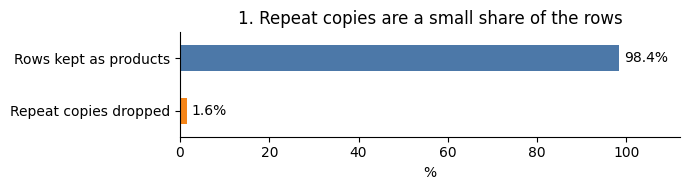

In [13]:
pct_bars(
    {
        "Rows kept as products": len(kept) / len(rows) * 100,
        "Repeat copies dropped": (len(rows) - len(kept)) / len(rows) * 100,
    },
    "1. Repeat copies are a small share of the rows",
    [BLUE, ORANGE],
)

**2. Weight**
- **What I did:** treated the fake number `999999999` as "unknown" and removed impossible weights.
- **Example:** stockings listed as "136 Kilograms" are removed. "1.4 Kg" becomes 1,400 g.
- **Why:** only about 1 in 5 products has a real weight, so it will matter very little.

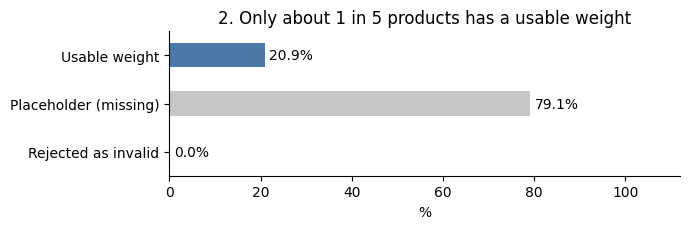

In [14]:
n = len(products)
usable = sum(p.weight_g is not None for p in products)
rejected = report.weight_problems
pct_bars(
    {
        "Usable weight": usable / n * 100,
        "Placeholder (missing)": problems["placeholder"] / n * 100,
        "Rejected as invalid": sum(rejected.values()) / n * 100,
    },
    "2. Only about 1 in 5 products has a usable weight",
    [BLUE, GREY, ORANGE],
    figsize=(7, 2.4),
)

**3. Brand**
- **What I did:** merged different spellings of the same brand and treated "Unknown" as missing.
- **Example:** "Print Mafias", "Print mafias" and "print mafias" become one brand.
- **Why:** so products from the same brand count as matching.

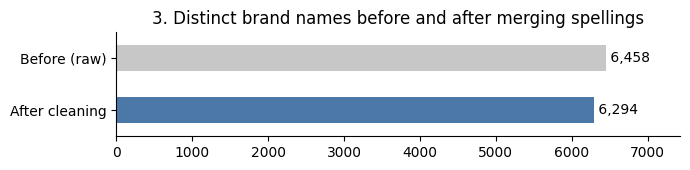

In [15]:
before = len(set(r.get("brand") for r in kept if r.get("brand")))
after = len({p.brand for p in products if p.brand})
ax = pd.Series({"After cleaning": after, "Before (raw)": before}).plot.barh(
    color=[BLUE, GREY], figsize=(7, 1.8)
)
for i, v in enumerate([after, before]):
    ax.text(v, i, f" {v:,}", va="center")
ax.set_xlim(0, before * 1.15)
ax.set_title("3. Distinct brand names before and after merging spellings")
plt.tight_layout()
plt.show()

**4. Category**
- **What I did:** when a category was missing, I copied the most common category of products on the same Amazon shelf.
- **Example:** "Pepe Jeans Boy's T-Shirt" had no category, so it got `BoysT_Shirts` from its shelf.
- **How I checked:** I covered up categories I already knew and guessed them back. It was right about 97 times out of 100. The misses were mostly close categories.
- **Why:** category is our strongest signal, and now almost every product has one.

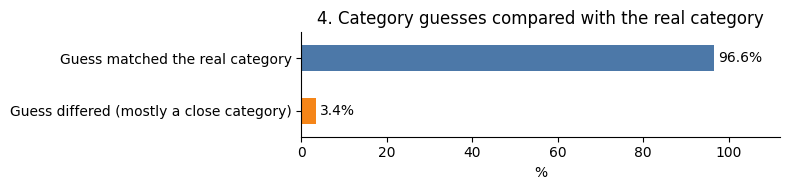

In [16]:
pct_bars(
    {
        "Guess matched the real category": facts["category_hit"] * 100,
        "Guess differed (mostly a close category)": (1 - facts["category_hit"]) * 100,
    },
    "4. Category guesses compared with the real category",
    [BLUE, ORANGE],
    figsize=(8, 2),
)

**5. Colour**
- **What I did:** the colour column lists every option, so I also read colour words from the title. Coverage rose from 19% to 44%.
- **Example:** a saree titled "Blue Sari" lists orange, pink and red, so the two sources can disagree.
- **Why:** colour is only a weak hint.

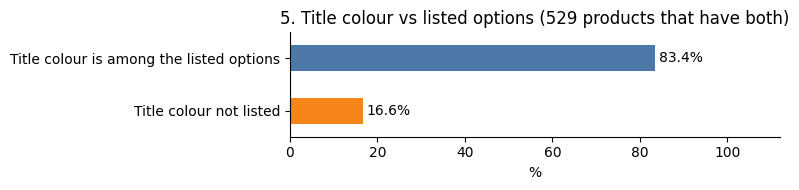

In [17]:
pct_bars(
    {
        "Title colour is among the listed options": facts["colour_agree"] * 100,
        "Title colour not listed": (1 - facts["colour_agree"]) * 100,
    },
    f"5. Title colour vs listed options ({len(both)} products that have both)",
    [BLUE, ORANGE],
    figsize=(8, 2),
)

**6. Audience (men, women, boys, girls, baby)**
- **What I did:** worked it out from the category, then the title. They agree about 89% of the time.
- **Example:** a boys' bow tie is filed under men's, so the label is wrong.
- **Why:** I use it as a hint, which raises the score without blocking other products. Tests will decide if a strict filter is better.

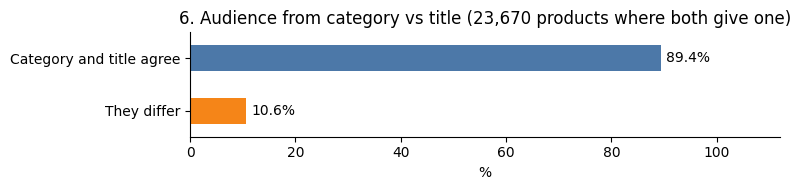

In [18]:
pct_bars(
    {
        "Category and title agree": facts["audience_agree"] * 100,
        "They differ": (1 - facts["audience_agree"]) * 100,
    },
    f"6. Audience from category vs title ({len(pairs):,} products where both give one)",
    [BLUE, ORANGE],
    figsize=(8, 2),
)

**7. Guessing a missing brand from the title (switched off)**
- **What I did:** built it and tested it on products whose brand I already know. It was right 98% of the time.
- **Example:** "Puma Unisex T-Shirt" has no brand, and the title starts with "Puma". But a Florsheim belt with "Stacy Adams" in its title would be wrong.
- **Why it's off:** I haven't verified it on products that really lack a brand.

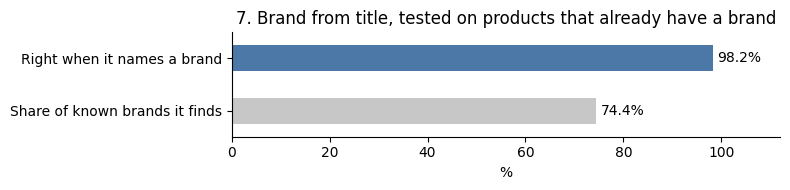

In [19]:
pct_bars(
    {
        "Right when it names a brand": facts["brand_precision"] * 100,
        "Share of known brands it finds": facts["brand_recall"] * 100,
    },
    "7. Brand from title, tested on products that already have a brand",
    [BLUE, GREY],
    figsize=(8, 2),
)

**8. Rating and price**
- **What I did:** kept the rating in three forms and the price in two. I haven't chosen how to use them yet.
- **Example:** a vest is rated 1.0, but its page says "Be the first to review this item". 6,571 products are like this.
- **Why:** testing will decide how to use them.

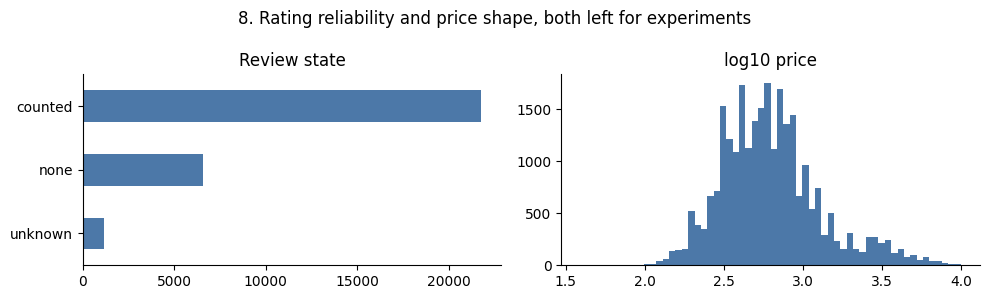

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
state = pd.Series([p.review_state for p in products]).value_counts()
state.iloc[::-1].plot.barh(ax=axes[0], color=BLUE)
axes[0].set_title("Review state")
axes[1].hist([p.log_price for p in products if p.log_price], bins=60, color=BLUE)
axes[1].set_title("log10 price")
fig.suptitle("8. Rating reliability and price shape, both left for experiments")
plt.tight_layout()
plt.show()

**Overall:** the data is strong on name, image, category, audience and price, and weak on weight, colour and rating. So the first group leads. Missing information stays missing, and two products are compared only on what both have.

**Next:** build the first working "find similar products" function, then the web service and Docker image.